In [151]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import random
%matplotlib inline

In [152]:
def f(x):
    return x**2+5*x+2

In [153]:
f(3)

26

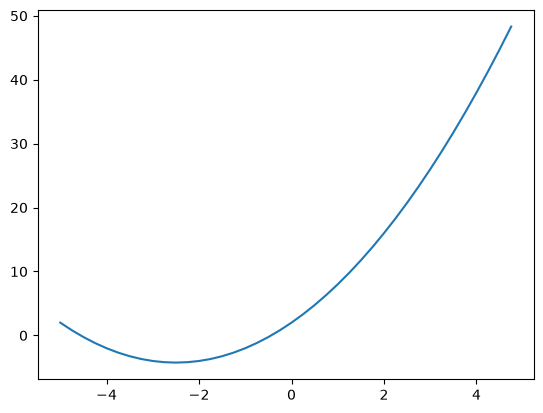

In [154]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [155]:
h = 0.00000000001
x=-2.5
(f(x+h)-f(x))/h

8.881784197001252e-05

In [156]:
a = 2
b = -3
c = 10
d = a*b+c
print(d)

4


In [157]:
h = 0.0001
a = 2
b = -3
c = 10
d1 = a*b+c
c+=h
d2 =  a*b+c
print("d1", d1)
print("d2", d2)
print("slope ",(d2-d1)/h )

d1 4
d2 4.0001
slope  0.9999999999976694


In [362]:
class Value:
    def __init__(self, data, children=(), _op='', label = ''):
        self.data = data
        self._prev = set(children)
        self._backward = lambda:None
        self._op = _op
        self.label = label
        self.grad = 0
    def __repr__(self):
        return f"Value(data={self.data})"
    def __neg__(self):
        return self*(-1)
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data+other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out
    def __sub__(self, other):
        return self+(-1*other)
    def __rmul__(self, other):
        return self*other
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data*other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    def __pow__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data**other.data, (self, other), '**')
        def _backward():
            self.grad += other.data*(self.data**(other.data-1))*out.grad
        out._backward = _backward
        return out
    def __truediv__(self, other):
        return self*(other**-1)
    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward
        return out
    def exp(self):
        out = Value(math.exp(self.data), (self,), 'exp')
        def _backward():
            self.grad+= out.data * out.grad
        out._backward = _backward
        return out
    def backward(self):
        topo = []
        visited = set()
        def topological_order(v):
            if v not in visited:
                visited.add(v)
                for c in v._prev:
                    topological_order(c)
                topo.append(v)
        topological_order(self)

        self.grad = 1.0
        for c in reversed(topo):
            c._backward()
    def __radd__(self, other):
        return self + other


    # def backprop(self, parent= None):
    #     if parent!= None: 
    #         self.grad *= parent.grad
    #         if parent._op=='+':
    #             self.grad*=1
    #         elif parent._op=='*':
    #             for child in parent._prev:
    #                 self.grad*= child.data
    #             self.grad/= self.data
    #         elif parent._op == 'tanh':
    #             self.grad = 1 - parent.data**2
    #     for child in self._prev:
    #         child.backprop(self)

        



a = Value(2.0, label='a')
b = Value(-3, label = 'b')
c = Value(10, label='c')
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'
d


Value(data=4.0)

In [159]:
from graphviz import Digraph
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad ), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)
  
  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  
  return dot

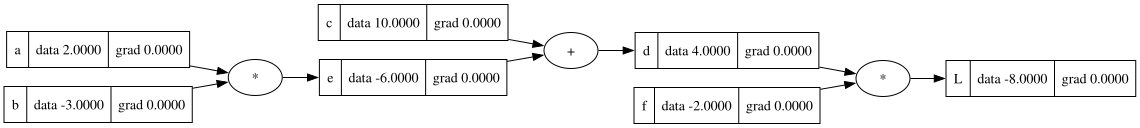

In [160]:
draw_dot(L)

In [161]:
def test():
    h=0.0001
    a = Value(2.0, label='a')
    b = Value(-3, label = 'b')
    c = Value(10, label='c')
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L1 = d*f; L.label = 'L'

    a = Value(2.0, label='a')
    b = Value(-3+h, label = 'b')
    c = Value(10, label='c')
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L2 = d*f; L.label = 'L'

    print((L2.data-L1.data)/h)
test()

-4.000000000008441


In [162]:
# Input x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.01, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label = 'w2')
# Bias b
b = Value(6.7, label = 'b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label = 'x1w1+x2w2'
n = x1w1x2w2+b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.backward()



In [163]:
# Input x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.01, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label = 'w2')
# Bias b
b = Value(6.7, label = 'b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label = 'x1w1+x2w2'
n = x1w1x2w2+b; n.label = 'n'
e = (2*n).exp(); e.label = 'e'
o = (e-1)/(e+1); o.label = 'o'

o.backward()



Value(data=4.137120440251392) 1


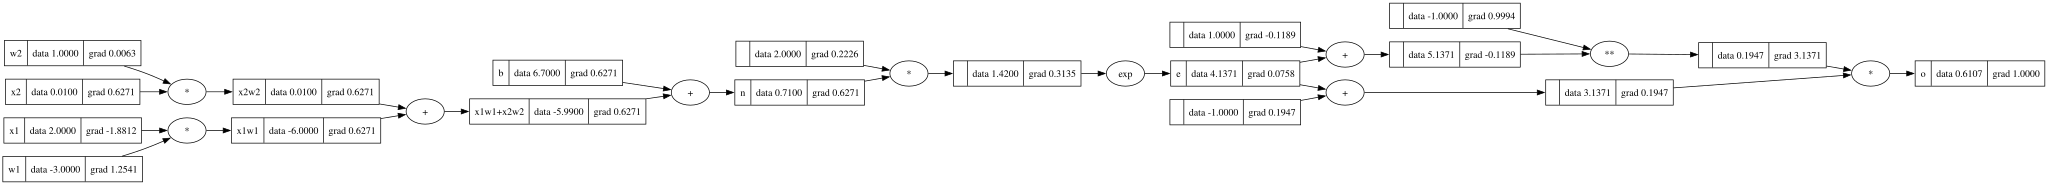

In [164]:
draw_dot(o)

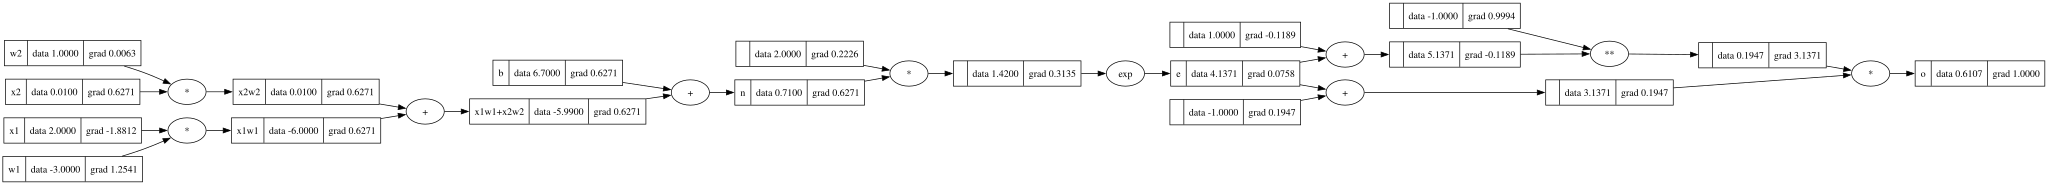

In [165]:
draw_dot(o)

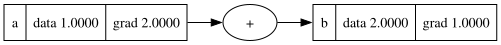

In [166]:
a = Value(1, label='a')
b = a+a; b.label = 'b'
b.backward()
draw_dot(b)

In [167]:
x1 = torch.Tensor([2.0]).double()               ;x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()               ;x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ;w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()               ;w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ;b.requires_grad = True
n = x1*w1+x2*w2+b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [212]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for i in range(nin)]
        self.b = Value(random.uniform(-1,1))
    def __call__(self, x):
        act = sum([xi*wi for xi, wi in zip(self.w, x)], self.b)
        out = act.tanh()
        return out
    def parameters(self):
        return self.w+[self.b]
class Layer:
    def __init__(self, nin, nneur):
        self.neurons = [Neuron(nin) for _ in range(nneur)]
    def __call__(self, x):
        outs = [neur(x) for neur in self.neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    def parameters(self):
        return [l for layer in self.layers for l in layer.parameters()]


In [366]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
n(x)

Value(data=-0.3632693474896638)

In [315]:
n.parameters()

[Value(data=-0.41640702610445857),
 Value(data=-0.3578436315044118),
 Value(data=-0.7381868895145833),
 Value(data=0.6943430242443354),
 Value(data=0.22282617031294283),
 Value(data=0.3160027359825157),
 Value(data=0.33515518963464586),
 Value(data=0.8698045643102075),
 Value(data=0.5712486925810731),
 Value(data=0.030887284977666685),
 Value(data=0.972425263231421),
 Value(data=-0.5975852878177876),
 Value(data=0.9755452391799464),
 Value(data=0.5408260314064333),
 Value(data=-0.6259791078673345),
 Value(data=-0.07523297987534394),
 Value(data=-0.4146308982916853),
 Value(data=-0.9921106064243945),
 Value(data=-0.6716182395756165),
 Value(data=0.20838375868853398),
 Value(data=0.552120888563431),
 Value(data=-0.7577665445458164),
 Value(data=0.43382290835529047),
 Value(data=0.4620247580962844),
 Value(data=0.38812233636515314),
 Value(data=0.8773973684420187),
 Value(data=0.1278341570013659),
 Value(data=0.22269497853475628),
 Value(data=-0.8641988989864839),
 Value(data=0.3492755435

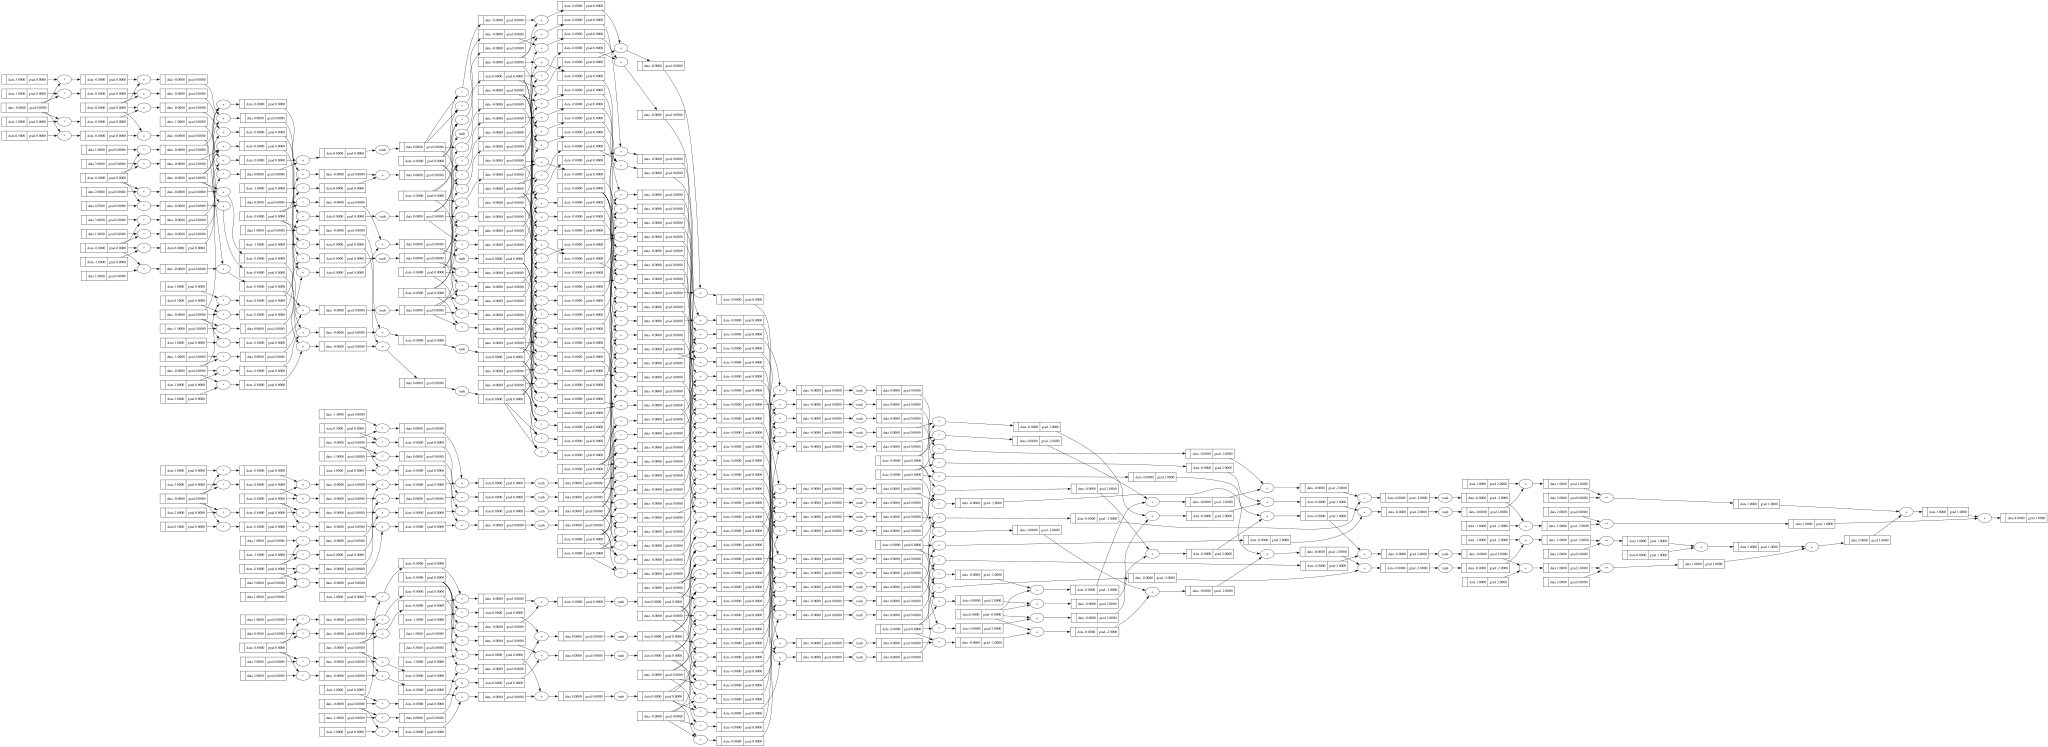

In [365]:
draw_dot(loss)

In [455]:
xs = [
    [2.0, 3.0, -1.0], 
    [3.0, -1.0, 0.5], 
    [0.5, 1.0, 1.0], 
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]
ypred = [n(x) for x in xs]
ypred

[Value(data=0.9947119712552933),
 Value(data=-0.9916253015781313),
 Value(data=-0.9923795632270258),
 Value(data=0.991574729034714)]

In [317]:
loss = sum([(pred-y)**2 for y, pred in zip(ys, ypred)])
loss 

Value(data=2.6141681600592017)

In [217]:
loss.backward()

In [ ]:
n.layers[0].neurons[0].w[0].grad

-0.012263199782414302

In [221]:
for p in n.parameters():
    p.data += -0.01*p.grad

In [220]:
n.layers[0].neurons[0].w[0].data

0.3805078444684562

In [345]:
ypred = [n(x) for x in xs]
loss = sum([(pred-y)**2 for y, pred in zip(ys, ypred)])
loss

Value(data=2.8291588930411074e-12)

In [346]:
loss.backward()
for p in n.parameters():
    p.data += -0.1*p.grad
ypred

[Value(data=0.9999992440921529),
 Value(data=-0.9999999095861055),
 Value(data=-0.9999999144438878),
 Value(data=0.999998322601904)]

In [300]:
grad_ls = [p.grad for p in n.parameters()]
grad_ls

[-0.011905956772844116,
 0.051157922341240926,
 -0.026359341145243003,
 0.02180654924168888,
 0.002279553375388872,
 0.00014028364447443695,
 -0.12182665091273341,
 -0.01445790933729141,
 0.3337555235233145,
 -0.10191497007468864,
 0.07654861920780238,
 0.1196744928043253,
 -0.342727049305113,
 0.16448085349301753,
 0.010605143074911701,
 -0.07471187796453543,
 0.006127788664619204,
 -0.04007211245022984,
 -0.014436104905318856,
 -0.0016315690189616695,
 -0.036746470258757,
 0.46046334572372777,
 1.03567318041273,
 0.5795779234109943,
 -0.12387807359498212,
 1.065060913082262,
 -0.08249571864154058,
 -0.6312094974654116,
 -0.21541359302332563,
 -0.03918294352545008,
 -0.6729930384134486,
 0.047009823965211264,
 -0.04040120113453211,
 0.0005244040171426123,
 -0.013873925093598083,
 -0.030737214268919812,
 2.3401789651031124,
 -2.0390137295436266,
 -1.271273437246915,
 1.7763971996992631,
 3.3215166391383155]

In [454]:
# training loop
for i in range(20):
    ypred = [n(x) for x in xs]
    loss = sum((y-yans)**2 for y, yans in zip(ypred, ys))

    # Important. Resets gradients to 0 so that new gradients are updated to it.
    for num in n.parameters():
        num.grad = 0.0
    loss.backward()

    for num in n.parameters():
        num.data += -0.05*num.grad
    print(i, loss)

0 Value(data=0.00022986757880203473)
1 Value(data=0.0002297304396869369)
2 Value(data=0.00022959346157483515)
3 Value(data=0.00022945664418405986)
4 Value(data=0.00022931998723359838)
5 Value(data=0.00022918349044309756)
6 Value(data=0.0002290471535328375)
7 Value(data=0.00022891097622377307)
8 Value(data=0.00022877495823748405)
9 Value(data=0.00022863909929620333)
10 Value(data=0.00022850339912280896)
11 Value(data=0.00022836785744081685)
12 Value(data=0.0002282324739743876)
13 Value(data=0.0002280972484483066)
14 Value(data=0.00022796218058801179)
15 Value(data=0.00022782727011956463)
16 Value(data=0.00022769251676966877)
17 Value(data=0.00022755792026563732)
18 Value(data=0.0002274234803354403)
19 Value(data=0.00022728919670765202)


In [350]:
n(x)

Value(data=0.9999999683441373)